<a href="https://colab.research.google.com/github/ashsiendo/DATA-201-Labs/blob/main/Assignments/Week8_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 8 Homework** - Ash Ibasan
We'll use the `Hitters` dataset from the lab in week 8 to see how changing the regularization strength (`α`) affects Lasso regression models, and look at training and test RMSE, how many predictors are kept, and how easy the model is to interpret.

The objective is to compare the results and consider when it makes sense to use ordinary linear regression, Ridge, or Lasso in different modeling scenarios.

> **Note to self: Comments throughout are used as guides, mainly for Python syntax, reasons why certain steps are used, and understanding and interpreting the results.**

## Setup - Data Preparation and Preprocessing

*We're going to be predicting professional baseball players' salaries using Lasso regression, and we'll utilize the following: prep the `Hitters` dataset, training/test split, and preprocessing steps*

In [2]:
%pip -q install ISLP

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# import relevant libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error

In [4]:
# load Hitters dataset
hitters = load_data('Hitters')
hitters = hitters.dropna(subset=['Salary']).copy() # remove rows with missing salary values

# define predictors (X); response variable (y)
X = hitters.drop(columns='Salary')
y = hitters['Salary']  # salary in thousands of dollars

# identify numerical and categorical predictors
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split( # training/test split
    X, y, test_size=0.25, random_state=42
)

print('Total observations:', len(X))
print('Training observations:', len(X_train))
print('Test observations:', len(X_test))
print('Categorical predictors:', cat_cols)

Total observations: 263
Training observations: 197
Test observations: 66
Categorical predictors: ['League', 'Division', 'NewLeague']


***Note to self:*** `Salary` is a continuous numeric response, so the problem is regression rather than classification. We'll be using RMSE to measure our prediction error rather than some classification metrics e.g., accuracy, precision, or recall

- `dropna(subset=['Salary'])` removes rows where the `Salary` value (response variable) is missing. Using `.copy()` makes a new DataFrame with the remaining data.

- `X` contains the predictor variables, and `y` is the response variable (`Salary`). We take `Salary` out of `X`, so we don't use the outcome as a predictor.

- `select_dtypes()` splits numerical and categorical predictors so we can preprocess them in different ways.

- `test_size=0.25` sets aside 25% of the data for testing, and `random_state=42` makes sure the split is the same each time we run the code.


We train the models using the training data. The test data then helps us see how well the models predict salaries for new cases.

In [5]:
def make_preprocessor(): # preprocessing function
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols),
            ('cat', OneHotEncoder(
                handle_unknown='ignore',
                drop='first'
            ), cat_cols)
        ]
    )

**Note to self:** Lasso penalizes coefficient sizes, so it's important to standardize numerical predictors. This way, we reduce the effect of differences in numerical predictor scales on regularization

- `StandardScaler()` is used to standardize numerical predictors
- `OneHotEncoder()` turns categorical variables into numerical indicator columns, so no artificial order is assigned
- Setting `drop='first'` removes one category from each categorical predictor to avoid redundant indicator columns
- The encoder can process categories in the test data that did not appear during training with `handle_unknown='ignore'`
- `ColumnTransformer` applies the right preprocessing steps to each group of predictors

Putting this preprocessor in a `Pipeline` makes sure that scaling and encoding are fitted only on the training data (not test data)



## Part 1 - Experiment with α

*I'll use the same training and test sets from the Week 8 lab to fit three Lasso regression models, each with a different regularization strength: `alpha = 0.1, 10, and 100`, and for each model, I'll compare training and test RMSE and also the number of nonzero coefficients (retained predictors). The goal is to find out how changing `alpha` affects the model complexity level and prediction performance*

*In Lasso (L1), increasing `alpha` makes regularization stronger, shrinking coefficients toward zero and removing predictors, but having fewer predictors does not always mean the model will perform better on new data*

In [6]:
alpha_values = [0.1, 10, 100]
rows = []

for a in alpha_values:
    pipe = Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', Lasso(alpha=a, max_iter=30000))
    ])

    pipe.fit(X_train, y_train)

    # calc training, test prediction errors
    train_rmse = np.sqrt(mean_squared_error(y_train, pipe.predict(X_train)))
    test_rmse = np.sqrt(mean_squared_error(y_test, pipe.predict(X_test)))

    # count coefficients that Lasso retains
    coefs = pipe.named_steps['model'].coef_
    nonzero = int(np.sum(np.abs(coefs) > 1e-6))

    # add each model's results to the table
    rows.append({
        'Alpha': a,
        'Training RMSE': train_rmse,
        'Test RMSE': test_rmse,
        'Nonzero coefficients': nonzero
    })

table_alpha = pd.DataFrame(rows)
display(table_alpha.round(2))

,Alpha,Training RMSE,Test RMSE,Nonzero coefficients
0,0.1,289.38,356.83,19
1,10.0,303.10,381.84,9
2,100.0,341.39,395.12,5


***Note to self:*** The `for` loop goes through each `alpha` value, fits a Lasso model, calculates the training and test RMSE, and counts how many coefficients are not zero each time. It then adds the results as `rows` (`append()`) and after the loop finishes, the results are converted into a `DataFrame` to compare all three models

**As α increases, what happens to the number of retained predictors?**

> _

**Does a smaller number of predictors always lead to a lower test RMSE?**

> _

## Part 2 - Visualize and Interpret
*We'll show how the three regularization strengths affect test RMSE using Part 1's results*

*Our goal is to see how changing `alpha` impacts prediction performance and to interpret the results in terms of the bias-variance trade-off*

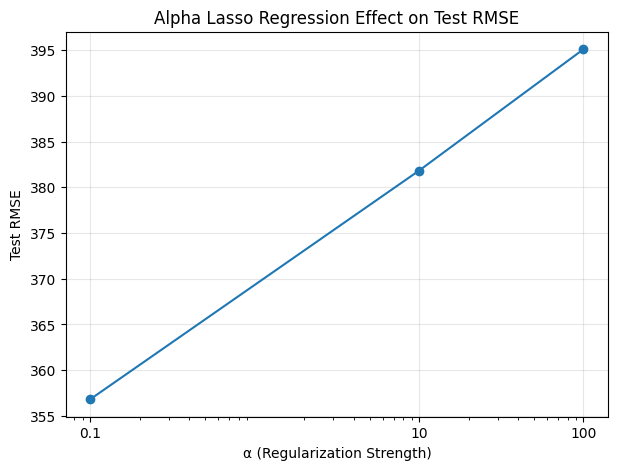

In [7]:
# plot test RMSE for each α value
plt.figure(figsize=(7, 5))

plt.plot(
    table_alpha['Alpha'],
    table_alpha['Test RMSE'],
    marker='o'
)

plt.xscale('log')  # show widely spaced α values on logarithmic scale
plt.xticks([0.1, 10, 100], ['0.1', '10', '100'])

plt.xlabel('α (Regularization Strength)')
plt.ylabel('Test RMSE')
plt.title('Alpha Lasso Regression Effect on Test RMSE')
plt.grid(True, alpha=0.3)

plt.show()

***Note to self:*** Regularization involves a bias–variance trade-off. Increasing `alpha` can  make the model simpler (reduce model complexity) and lower variance, but excessive regularization can increase bias and lead to underfitting

Both training and test RMSE increased as `alpha` increased in this experiment, but that pattern doesn’t mean regularization always worsens test results. Its effect depends on the data, the model, and how much regularization is used

**Which α produces the lowest test RMSE?**
> _

**Which α appears to cause the most underfitting? Explain using bias.**

> _

**Why might a model with higher training RMSE produce lower test RMSE?**
> _

## Part 3 - Interpret the Model

*Let's review the Lasso model with `alpha = 100` from Part 1 to find out which predictors were removed by regularization*

*We want to see what zero coefficients mean and how having fewer predictors changes how we interpret the model*


In [8]:
# fit Lasso using alpha = 100
pipe_100 = Pipeline([
    ('preprocess', make_preprocessor()),
    ('model', Lasso(alpha=100, max_iter=30000))
])

pipe_100.fit(X_train, y_train)

# get feature names and fitted coefficients
feature_names = pipe_100.named_steps['preprocess'].get_feature_names_out()
coefs = pipe_100.named_steps['model'].coef_

# create table showing each feature's coefficient
coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs
})

# identify coefficients treated as zero
zero_coefs = coef_table.loc[np.abs(coef_table['Coefficient']) <= 1e-6]
display(zero_coefs.round(4))

,Feature,Coefficient
0,num__AtBat,0.0
2,num__HmRun,0.0
3,num__Runs,0.0
4,num__RBI,0.0
6,num__Years,0.0
7,num__CAtBat,0.0
8,num__CHits,0.0
9,num__CHmRun,0.0
12,num__CWalks,0.0
14,num__Assists,0.0


***Note to self:*** `.coef_` gives the coefficients from the fitted Lasso model, and `get_feature_names_out()` lists the feature names after preprocessing.

If `.loc[]` is used with `np.abs(...) <= 1e-6`, it will filter the table down to just the coefficients that are zero or almost zero.

When `alpha = 100`, Lasso sets 14 coefficients to zero and keeps 5 non-zero, matching what we saw in Part 1; the model doesn't use those 14 features to predict salary, but that doesn't mean those features have no connection to salary.

**Identify two predictors that Lasso sets to zero at α = 100.**

> _

**Does setting their coefficients to zero prove these predictors have no relationship with salary? Explain.**
> _

**If two models have very similar test RMSE but one uses fewer predictors, which would you prefer? Explain in terms of interpretability and predictive performance.**
> _